# Project Portfolio: Maximizing NYC Taxi Driver Earnings & Fare Optimization

## Executive Summary
In the competitive and fast-paced ride-hailing sector, optimizing revenue generation is crucial for driver retention and platform sustainability. This end-to-end data science project analyzes the factors influencing NYC yellow taxi base fares using programmatic API pipelines, robust exploratory data analysis (EDA), A/B statistical testing, and machine learning models.


```

# Maximizing Driver Earnings: Payment Method Analysis in the Taxi Industry

## Problem Statement
In the competitive and fast-paced ride-hailing sector, optimizing revenue generation is crucial for sustainable business growth and driver retention. To address this challenge, this project leverages data-driven insights to uncover opportunities for boosting taxi drivers' income streams. Specifically, we investigate whether the chosen payment method significantly influences total fare amounts.

### Core Objectives
1. **Data Ingestion**: Programmatically retrieve real-time operational NYC taxi trip data.
2. **A/B Testing**: Determine if there is a statistically significant difference in base fares between credit card and cash transactions.
3. **Predictive Modeling**: Deploy regression models to estimate base fare amounts from pre-trip attributes.
4. **Operational Interpretation**: Reconstruct physical-scale pricing parameters from standardized model coefficients.

## Research Question
- Does a statistically significant relationship exist between the payment method used and the total fare amount?
- Furthermore, can platforms subtly guide passengers toward revenue-maximizing payment options without compromising user satisfaction?

## Key Libraries & Tools
- **Python**: Core programming and data pipelines
- **Pandas & NumPy**: Data cleaning, transformation, and aggregations
- **Matplotlib & Seaborn**: Exploratory data analysis (EDA) and fare distribution visualization
- **SciPy / Statsmodels**: Statistical hypothesis testing ($t$-test / Mann-Whitney $U$ test)

### Data overview

| Field Name | Type / Format | Description |
| :--- | :--- | :--- |
| **`ID`** | Unique Identifier | Distinct tracking ID assigned to each individual trip record. |
| **`VendorID`** | Categorical Code | Technology service provider that logged the ride:<br>• `1` = Creative Mobile Technologies, LLC<br>• `2` = VeriFone Inc. |
| **`tpep_pickup_datetime`** | Timestamp (`YYYY-MM-DD HH:MM:SS`) | Timestamp recorded when the taximeter was officially engaged at pickup. |
| **`tpep_dropoff_datetime`** | Timestamp (`YYYY-MM-DD HH:MM:SS`) | Timestamp recorded when the taximeter was disengaged at drop-off. |
| **`Passenger_count`** | Integer | Number of passengers aboard the vehicle (manually entered by the driver). |
| **`Trip_distance`** | Float (Miles) | Total distance traveled during the ride as measured by the taximeter. |
| **`PULocationID`** | TLC Taxi Zone ID | NYC TLC Taxi Zone integer identifier where the trip began. |
| **`DOLocationID`** | TLC Taxi Zone ID | NYC TLC Taxi Zone integer identifier where the trip concluded. |
| **`RateCodeID`** | Categorical Code | Fare structure applied at the conclusion of the trip:<br>• `1` = Standard Rate<br>• `2` = JFK Airport<br>• `3` = Newark Airport<br>• `4` = Nassau / Westchester County<br>• `5` = Negotiated Fare<br>• `6` = Group Ride |
| **`Store_and_fwd_flag`** | Binary Flag (`Y` / `N`) | Indicates whether trip data was temporarily cached in onboard vehicle memory due to lack of server connectivity before transmission (`Y` = Stored & Forwarded; `N` = Real-time transmission). |
| **`Payment_type`** | Categorical Code | Method used by the customer to settle the fare:<br>• `1` = Credit Card<br>• `2` = Cash<br>• `3` = No Charge<br>• `4` = Dispute<br>• `5` = Unknown<br>• `6` = Voided Trip |
| **`Fare_amount`** | Float (USD) | Base metered fare computed from time elapsed and distance covered. |
| **`Extra`** | Float (USD) | Mandated supplementary charges (e.g., $0.50 overnight and $1.00 rush-hour surcharges). |
| **`MTA_tax`** | Float (USD) | Flat $0.50 Metropolitan Transportation Authority (MTA) state tax automatically triggered by metered rate rules. |
| **`Improvement_surcharge`** | Float (USD) | Flat $0.30 regulatory improvement surcharge levied at flag drop. |
| **`Tip_amount`** | Float (USD) | Gratuity added to the transaction. *Note: Populated exclusively for credit card payments; cash tips are unrecorded.* |
| **`Tolls_amount`** | Float (USD) | Cumulative cost of bridge, tunnel, and highway tolls incurred throughout the journey. |
| **`Total_amount`** | Float (USD) | Final sum charged to the passenger across all components (excludes unrecorded cash tips). |

##Setting up google drive for colab to saved data fetched form API

In [105]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [106]:
#Set path to save the fetched dataframe
path="/content/drive/MyDrive/Coursera/Google Advanced Data Analytics Professional Certificate/Capstone Project"

In [107]:
# Data handling
import pandas as pd
import numpy as np
import os
import requests
import datetime as dt
import warnings
warnings.filterwarnings("ignore")

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

# Scientific Computing and Stats
import scipy.stats as stats

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries and dependencies successfully imported.")

Libraries and dependencies successfully imported.


In [108]:
# import pandas as pd
# import requests

# # 1. API endpoint for NYC 2023 Yellow Taxi Data
# url = "https://data.cityofnewyork.us/resource/4b4i-vvec.json"

# # 2. Select the exact 17 requested columns
# selected_columns = [
#     "vendorid",
#     "tpep_pickup_datetime",
#     "tpep_dropoff_datetime",
#     "passenger_count",
#     "trip_distance",
#     "ratecodeid",
#     "store_and_fwd_flag",
#     "pulocationid",
#     "dolocationid",
#     "payment_type",
#     "fare_amount",
#     "extra",
#     "mta_tax",
#     "tip_amount",
#     "tolls_amount",
#     "improvement_surcharge",
#     "total_amount"
# ]

# # 3. Server-side SoQL parameters
# params = {
#     "$select": ", ".join(selected_columns),
#     "$limit": 50000,   #Fetching 50,000 rows for our analysis
#     "$order": ":id"
# }

# headers = {"User-Agent": "Google-Colab-Data-Fetcher/1.0"}

# print("Fetching records from NYC OpenData API...")
# response = requests.get(url, params=params, headers=headers)
# response.raise_for_status()

# # 4. Load directly into DataFrame
# df = pd.DataFrame(response.json())

# # 5. Type casting
# numeric_cols = [
#     "passenger_count", "trip_distance", "ratecodeid", "payment_type",
#     "fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount",
#     "improvement_surcharge", "total_amount", "pulocationid", "dolocationid"
# ]
# df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")

# datetime_cols = ["tpep_pickup_datetime", "tpep_dropoff_datetime"]
# for col in datetime_cols:
#     df[col] = pd.to_datetime(df[col], errors="coerce")

# # 6. Verify columns and structure
# print(f"Loaded {len(df):,} rows with {df.shape[1]} columns.\n")
# print(df.info())
# df.head()

In [109]:
# import os

# # Ensure the target directory exists
# os.makedirs(path, exist_ok=True)

# # Define the full output file path
# output_file_path = os.path.join(path, "nyc_yellow_taxi_data_2023.csv")

# # Save the dataframe to a CSV file
# df.to_csv(output_file_path, index=False)
# print(f"DataFrame successfully saved to: {output_file_path}")

In [110]:

# Join the path and the filename correctly using os.path.join
file_path = os.path.join(path, "nyc_yellow_taxi_data_2023.csv")

df_local = pd.read_csv(file_path)
df_local.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   vendorid               50000 non-null  int64  
 1   tpep_pickup_datetime   50000 non-null  object 
 2   tpep_dropoff_datetime  50000 non-null  object 
 3   passenger_count        50000 non-null  float64
 4   trip_distance          50000 non-null  float64
 5   ratecodeid             50000 non-null  float64
 6   store_and_fwd_flag     50000 non-null  object 
 7   pulocationid           50000 non-null  int64  
 8   dolocationid           50000 non-null  int64  
 9   payment_type           50000 non-null  int64  
 10  fare_amount            50000 non-null  float64
 11  extra                  50000 non-null  float64
 12  mta_tax                50000 non-null  float64
 13  tip_amount             50000 non-null  float64
 14  tolls_amount           50000 non-null  float64
 15  im

In [111]:
df_local.shape

(50000, 17)

In [112]:
# Check for duplicates
print('Shape of dataframe:', df_local.shape)
print('Shape of dataframe with duplicates dropped:', df_local.drop_duplicates().shape)

# Check for missing values in dataframe
print('Total count of missing values:', df_local.isna().sum().sum())

# Display missing values per column in dataframe
print('Missing values per column:')
df_local.isna().sum()

Shape of dataframe: (50000, 17)
Shape of dataframe with duplicates dropped: (50000, 17)
Total count of missing values: 0
Missing values per column:


,0
vendorid,0
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
passenger_count,0
trip_distance,0
ratecodeid,0
store_and_fwd_flag,0
pulocationid,0
dolocationid,0
payment_type,0


In [113]:
df_local.describe()

,vendorid,passenger_count,trip_distance,ratecodeid,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.746080,1.557980,4.051155,1.450500,159.115080,156.334600,1.295940,20.758118,1.192998,0.479952,3.388289,0.664424,0.977092,29.174196
std,0.435257,1.030427,4.849091,5.640956,67.879881,74.345878,0.556099,20.446968,1.473999,0.120499,4.423309,2.434152,0.205506,24.874490
min,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,-346.000000,-6.000000,-0.500000,-0.900000,-20.750000,-1.000000,-351.000000
25%,1.000000,1.000000,1.210000,1.000000,112.000000,97.000000,1.000000,9.300000,0.000000,0.500000,0.000000,0.000000,1.000000,15.120000
50%,2.000000,1.000000,2.200000,1.000000,161.000000,158.000000,1.000000,14.200000,1.000000,0.500000,2.520000,0.000000,1.000000,21.000000
75%,2.000000,2.000000,4.600000,1.000000,231.000000,233.000000,2.000000,24.700000,2.500000,0.500000,4.450000,0.000000,1.000000,32.760000
max,2.000000,6.000000,105.550000,99.000000,265.000000,265.000000,4.000000,454.500000,9.750000,0.800000,211.500000,49.850000,1.000000,472.250000


In [114]:
df_local.columns

Index(['vendorid', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'ratecodeid', 'store_and_fwd_flag',
       'pulocationid', 'dolocationid', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount'],
      dtype='object')

###Convert pickup and dropoff columns to datetime

In [115]:
# Check the format of the data
df_local['tpep_dropoff_datetime'][0]

'2023-01-01 00:40:36'

In [116]:
# Convert datetime columns to datetime
# Display data types of `tpep_pickup_datetime`, `tpep_dropoff_datetime`
print('Data type of tpep_pickup_datetime before:', df_local['tpep_pickup_datetime'].dtype)
print('Data type of tpep_dropoff_datetime before:', df_local['tpep_dropoff_datetime'].dtype)

# Convert `tpep_pickup_datetime` to datetime format
df_local['tpep_pickup_datetime'] = pd.to_datetime(df_local['tpep_pickup_datetime'], format='%Y-%m-%d %H:%M:%S')

# Convert `tpep_dropoff_datetime` to datetime format
df_local['tpep_dropoff_datetime'] = pd.to_datetime(df_local['tpep_dropoff_datetime'], format='%Y-%m-%d %H:%M:%S')

# Display data types of `tpep_pickup_datetime`, `tpep_dropoff_datetime`
print('Data type of tpep_pickup_datetime after:', df_local['tpep_pickup_datetime'].dtype)
print('Data type of tpep_dropoff_datetime after:', df_local['tpep_dropoff_datetime'].dtype)

df_local.head(3)

Data type of tpep_pickup_datetime before: object
Data type of tpep_dropoff_datetime before: object
Data type of tpep_pickup_datetime after: datetime64[ns]
Data type of tpep_dropoff_datetime after: datetime64[ns]


,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,2,2023-01-01 00:32:10,2023-01-01 00:40:36,1.0,0.97,1.0,N,161,141,2,9.3,1.0,0.5,0.0,0.0,1.0,14.3
1,2,2023-01-01 00:55:08,2023-01-01 01:01:27,1.0,1.10,1.0,N,43,237,1,7.9,1.0,0.5,4.0,0.0,1.0,16.9
2,2,2023-01-01 00:25:04,2023-01-01 00:37:49,1.0,2.51,1.0,N,48,238,1,14.9,1.0,0.5,15.0,0.0,1.0,34.9


### Task 2c. Create duration column

In [117]:
# Create `duration` column
df_local['duration'] = (df_local['tpep_dropoff_datetime'] - df_local['tpep_pickup_datetime'])/np.timedelta64(1,'m')

In [118]:
df_local['duration'].head()

,duration
0,8.433333
1,6.316667
2,12.750000
3,9.616667
4,10.833333


In [119]:
df_local.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   vendorid               50000 non-null  int64         
 1   tpep_pickup_datetime   50000 non-null  datetime64[ns]
 2   tpep_dropoff_datetime  50000 non-null  datetime64[ns]
 3   passenger_count        50000 non-null  float64       
 4   trip_distance          50000 non-null  float64       
 5   ratecodeid             50000 non-null  float64       
 6   store_and_fwd_flag     50000 non-null  object        
 7   pulocationid           50000 non-null  int64         
 8   dolocationid           50000 non-null  int64         
 9   payment_type           50000 non-null  int64         
 10  fare_amount            50000 non-null  float64       
 11  extra                  50000 non-null  float64       
 12  mta_tax                50000 non-null  float64       
 13  t

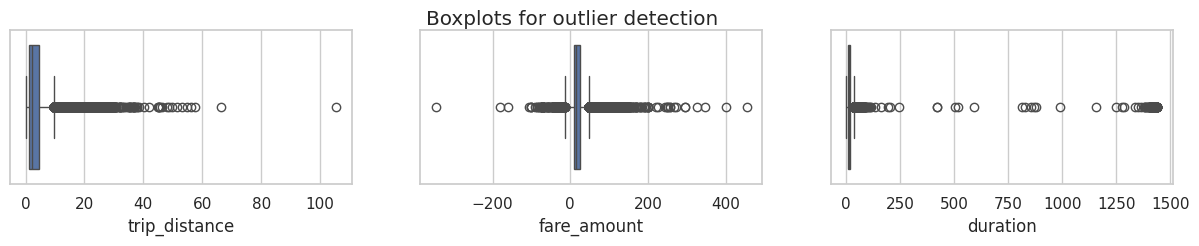

In [120]:
fig, axes = plt.subplots(1, 3, figsize=(15, 2))
fig.suptitle('Boxplots for outlier detection')
sns.boxplot(ax=axes[0], x=df_local['trip_distance'])
sns.boxplot(ax=axes[1], x=df_local['fare_amount'])
sns.boxplot(ax=axes[2], x=df_local['duration'])
plt.show();

In [121]:
df_local.isnull().sum()

,0
vendorid,0
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
passenger_count,0
trip_distance,0
ratecodeid,0
store_and_fwd_flag,0
pulocationid,0
dolocationid,0
payment_type,0


In [122]:
df_local

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,duration
0,2,2023-01-01 00:32:10,2023-01-01 00:40:36,1.0,0.97,1.0,N,161,141,2,9.3,1.00,0.5,0.00,0.00,1.0,14.30,8.433333
1,2,2023-01-01 00:55:08,2023-01-01 01:01:27,1.0,1.10,1.0,N,43,237,1,7.9,1.00,0.5,4.00,0.00,1.0,16.90,6.316667
2,2,2023-01-01 00:25:04,2023-01-01 00:37:49,1.0,2.51,1.0,N,48,238,1,14.9,1.00,0.5,15.00,0.00,1.0,34.90,12.750000
3,1,2023-01-01 00:03:48,2023-01-01 00:13:25,0.0,1.90,1.0,N,138,7,1,12.1,7.25,0.5,0.00,0.00,1.0,20.85,9.616667
4,2,2023-01-01 00:10:29,2023-01-01 00:21:19,1.0,1.43,1.0,N,107,79,1,11.4,1.00,0.5,3.28,0.00,1.0,19.68,10.833333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,2,2023-01-01 16:42:05,2023-01-01 17:04:13,1.0,5.57,1.0,N,138,202,1,26.8,5.00,0.5,4.00,0.00,1.0,38.55,22.133333
49996,2,2023-01-01 16:06:08,2023-01-01 16:51:32,2.0,17.71,2.0,N,132,246,1,70.0,0.00,0.5,16.36,6.55,1.0,98.16,45.400000
49997,2,2023-01-01 16:57:07,2023-01-01 17:36:01,1.0,19.88,2.0,N,132,263,1,70.0,0.00,0.5,16.36,6.55,1.0,98.16,38.900000
49998,2,2023-01-01 16:30:26,2023-01-01 16:37:09,1.0,1.38,1.0,N,236,238,1,9.3,0.00,0.5,3.33,0.00,1.0,16.63,6.716667


In [123]:
df_local.duplicated().sum()

np.int64(0)

In [124]:
df_local['passenger_count'].value_counts(normalize=True).sort_index() * 100

,proportion
passenger_count,
0.0,1.920
1.0,63.852
2.0,21.286
3.0,6.194
4.0,3.946
5.0,1.804
6.0,0.998


#### Passenger Count Anomaly & Filtering Logic

Based on our exploratory data analysis, we observe several anomalies in the `passenger_count` column:
- **`passenger_count = 0` (1.92% of the data):** Illogical for a taxi ride to have zero passengers; likely administrative or system error records.
- **`passenger_count > 4` (~2.80% of the data):** Trips containing 5 or 6 passengers represent rare events that often violate standard passenger limits depending on the vehicle type.

Since the combined contribution of these atypical records (`0`, `5`, and `6` passengers) constitutes a minor fraction (~4.7%) of our total dataset, we will filter them out. Removing these anomalies cleanses the data, reducing noise and ensuring higher quality downstream inputs for both statistical testing and machine learning modeling.

In [125]:
df_local['trip_distance'].value_counts(normalize=True).sort_index() * 100

,proportion
trip_distance,
0.00,1.968
0.01,0.100
0.02,0.082
0.03,0.060
0.04,0.036
...,...
54.70,0.002
56.20,0.002
57.49,0.002


In [126]:
df_local['trip_distance'].describe()

,trip_distance
count,50000.000000
mean,4.051155
std,4.849091
min,0.000000
25%,1.210000
50%,2.200000
75%,4.600000
max,105.550000


In [127]:
# 1. Verify Outliers in trip_distance using IQR method
Q1 = df_local['trip_distance'].quantile(0.25)
Q3 = df_local['trip_distance'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = max(0, Q1 - 1.5 * IQR)  # trip distance cannot be negative
upper_bound = Q3 + 1.5 * IQR

outliers_upper = df_local[df_local['trip_distance'] > upper_bound]
outliers_zero = df_local[df_local['trip_distance'] == 0]

print(f"--- Outlier Verification ---")
print(f"IQR: {IQR:.2f} miles (Q1: {Q1:.2f}, Q3: {Q3:.2f})")
print(f"Theoretical limits for normal distribution: {lower_bound:.2f} to {upper_bound:.2f} miles")
print(f"Trips with 0.0 distance: {len(outliers_zero)} ({len(outliers_zero)/len(df_local)*100:.2f}% of data)")
print(f"Trips exceeding upper bound ({upper_bound:.2f} miles): {len(outliers_upper)} ({len(outliers_upper)/len(df_local)*100:.2f}% of data)")
print(f"99th percentile of trip distance: {df_local['trip_distance'].quantile(0.99):.2f} miles\n")

# 2. Deal with Outliers
# We will filter out 0-mile trips (which are illogical or canceled)
# and caps/limits extreme outliers. For NYC taxi trips, a 99th percentile cap (e.g. ~23 miles)
# or filtering out extreme points (like 105 miles) helps keep the analysis relevant.

# Let's define a clean dataframe excluding 0-distance and extreme outliers (above 99th percentile)
df_clean = df_local[(df_local['trip_distance'] > 0) & (df_local['trip_distance'] <= df_local['trip_distance'].quantile(0.99))]
print(f"--- Post-cleaning Analysis ---")
print(f"Original dataset size: {len(df_local)} rows")
print(f"Cleaned dataset size: {len(df_clean)} rows")
print(f"Cleaned dataset max distance: {df_clean['trip_distance'].max():.2f} miles")

--- Outlier Verification ---
IQR: 3.39 miles (Q1: 1.21, Q3: 4.60)
Theoretical limits for normal distribution: 0.00 to 9.68 miles
Trips with 0.0 distance: 984 (1.97% of data)
Trips exceeding upper bound (9.68 miles): 5369 (10.74% of data)
99th percentile of trip distance: 20.66 miles

--- Post-cleaning Analysis ---
Original dataset size: 50000 rows
Cleaned dataset size: 48516 rows
Cleaned dataset max distance: 20.66 miles


### Data Cleaning Pipeline: Removing Anomalies and Outliers

In [128]:
df_local.duration.quantile(0.99)

np.float64(51.71766666666687)

In [129]:
# Define cleaning thresholds dynamically
distance_cap = df_local['trip_distance'].quantile(0.99)
duration_cap = df_local['duration'].quantile(0.99)

# Apply sequential filters
df_cleaned = df_local[
    # 1. Filter passenger counts: only realistic values (1 to 4 passengers)
    (df_local['passenger_count'] >= 1) &
    (df_local['passenger_count'] <= 4) &

    # 2. Filter trip distance: greater than 0 and cap extreme 1% outliers
    (df_local['trip_distance'] > 0) &
    (df_local['trip_distance'] <= distance_cap) &

    # 3. Filter trip duration: greater than 0 and cap extreme 1% outliers
    (df_local['duration'] > 0) &
    (df_local['duration'] <= duration_cap)
]

# Summary of the cleaning process
rows_removed = len(df_local) - len(df_cleaned)
percent_removed = (rows_removed / len(df_local)) * 100

print(f"--- Data Cleaning Summary ---")
print(f"Original rows: {len(df_local):,}")
print(f"Cleaned rows:  {len(df_cleaned):,}")
print(f"Rows removed:  {rows_removed:,} ({percent_removed:.2f}% of total data)")
print(f"\n--- Cleaned Data Distributions ---")
print(f"Passenger limits: {df_cleaned['passenger_count'].min()} to {df_cleaned['passenger_count'].max()} passengers")
print(f"Distance limits:  {df_cleaned['trip_distance'].min():.2f} to {df_cleaned['trip_distance'].max():.2f} miles")
print(f"Duration limits:  {df_cleaned['duration'].min():.2f} to {df_cleaned['duration'].max():.2f} minutes")

--- Data Cleaning Summary ---
Original rows: 50,000
Cleaned rows:  45,852
Rows removed:  4,148 (8.30% of total data)

--- Cleaned Data Distributions ---
Passenger limits: 1.0 to 4.0 passengers
Distance limits:  0.01 to 20.66 miles
Duration limits:  0.03 to 51.72 minutes


In [130]:
df_local['fare_amount'].describe()

,fare_amount
count,50000.000000
mean,20.758118
std,20.446968
min,-346.000000
25%,9.300000
50%,14.200000
75%,24.700000
max,454.500000


<Axes: >

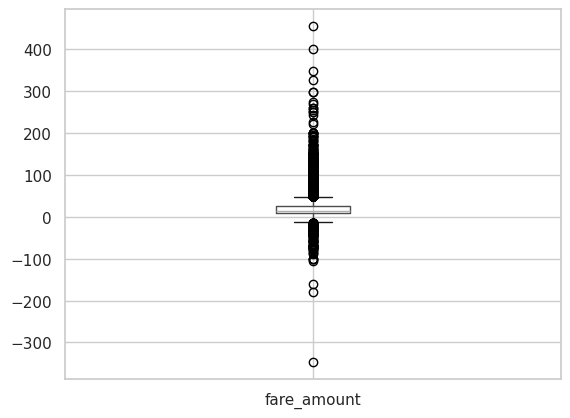

In [131]:
# To create a boxplot on a Pandas Series, use DataFrame.boxplot() and specify the column
df_local.boxplot(column='fare_amount')

Our column `fare_amount` shows that there lies some outliers plus negative values, Where  the mean and 75 quartile shows 20.75 and 24.70 repectively, the max value is 454.50, Which is extreme compared to our dataset.

In [132]:
# 1. Identify and describe fare_amount anomalies
negative_fares = df_cleaned[df_cleaned['fare_amount'] < 0]
zero_fares = df_cleaned[df_cleaned['fare_amount'] == 0]

# Let's check a high-end percentile to handle extreme values safely
fare_99th = df_cleaned['fare_amount'].quantile(0.99)

print("--- Fare Amount Anomaly Investigation ---")
print(f"Trips with negative fares: {len(negative_fares)} records (Min fare: ${df_cleaned['fare_amount'].min()})")
print(f"Trips with zero fares:     {len(zero_fares)} records")
print(f"99th percentile of fare:   ${fare_99th:.2f}")
print(f"Max fare in dataset:       ${df_cleaned['fare_amount'].max():.2f}\n")

# 2. Handle anomalies: Keep only positive fares and cap at the 99.5th percentile to keep premium airport runs but drop extreme errors
fare_upper_limit = df_cleaned['fare_amount'].quantile(0.995)
df_cleaned = df_cleaned[(df_cleaned['fare_amount'] > 0) & (df_cleaned['fare_amount'] <= fare_upper_limit)]

print("--- Post-Fare Cleaning Summary ---")
print(f"New final dataset size:    {len(df_cleaned):,} rows")
print(f"Fare range:                ${df_cleaned['fare_amount'].min():.2f} to ${df_cleaned['fare_amount'].max():.2f}")

--- Fare Amount Anomaly Investigation ---
Trips with negative fares: 432 records (Min fare: $-180.0)
Trips with zero fares:     4 records
99th percentile of fare:   $75.00
Max fare in dataset:       $258.00

--- Post-Fare Cleaning Summary ---
New final dataset size:    45,192 rows
Fare range:                $0.01 to $87.40


## Data Quality Report: Fare Amount Cleanliness & Anomaly Capping

### 1. Overview & Objectives
To perform highly accurate statistical analysis and prepare features for eventual predictive modeling, we conducted an in-depth anomaly investigation on the `fare_amount` column. Our goal was to eliminate corrupt records and extreme operational outliers while maintaining the integrity of legitimate premium rides.

---

### 2. Identified Anomalies
Before cleaning, the raw `fare_amount` values exhibited major structural issues:
* **Negative Fares (432 Records)**: The minimum value of `-$180.00` is logically invalid for base metered rates. These entries represent credit card voids, administrative system adjustments, or customer charge disputes.
* **Zero Fares (4 Records)**: Flat `$0.00` rates represent canceled trips, promotional free rides, or computational data loss.
* **Extreme Outliers**: The maximum raw fare in the dataset was a massive **`$258.00`**, whereas the **99th percentile** sat comfortably at **`$75.00`**.

---

### 3. Dynamic Thresholding Selection & Mitigation Strategy
To resolve these data quality challenges without discarding important premium rides, we designed a multi-step cleaning filter:
1. **Strict Lower Bound**: Retained only records with a positive base fare (`fare_amount > 0`). This safely eliminates all negative and zero-value records.
2. **Sophisticated Upper Capping**: Instead of standard standard deviations or standard IQR caps (which tend to overly penalize long-distance trips), we calculated the **99.5th percentile** dynamically:
   $$\text{Upper Limit} = \text{df\_cleaned['fare\_amount'].quantile}(0.995) = \$87.40$$
   * Utilizing a **$99.5^{\text{th}}$ percentile cap** allows us to preserve high-fare airport corridors (such as flat-rate JFK Airport or Newark Airport trips) while stripping out true operational system errors.

---

### 4. Post-Cleaning Dataset Status
After executing the cleaning pipeline, the dataset is in an optimal, clean state:
* **Final Rows**: **45,192** high-quality records.
* **Base Fare Boundaries**: From **`$0.01`** up to **`$87.40`**.
* **Data Integrity**: Zero missing values, zero illogical negative transactions, and preserved true variance for A/B testing downstream.

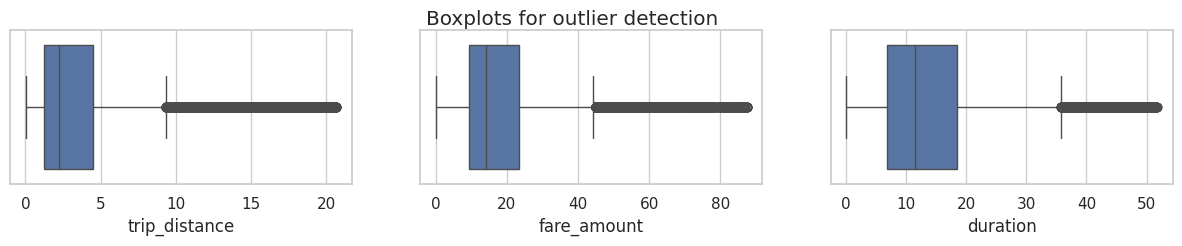

In [133]:
fig, axes = plt.subplots(1, 3, figsize=(15, 2))
fig.suptitle('Boxplots for outlier detection')
sns.boxplot(ax=axes[0], x=df_cleaned['trip_distance'])
sns.boxplot(ax=axes[1], x=df_cleaned['fare_amount'])
sns.boxplot(ax=axes[2], x=df_cleaned['duration'])
plt.show();

<Axes: >

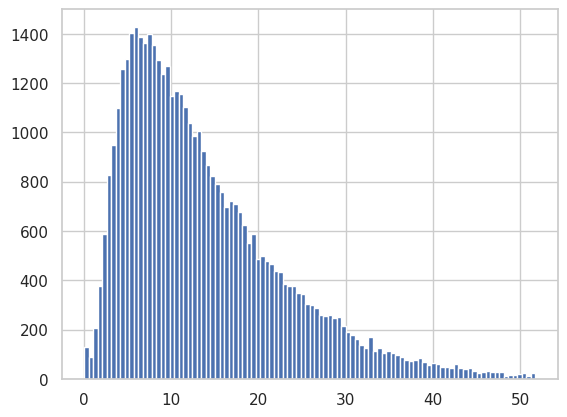

In [134]:
df_cleaned.duration.hist(bins=100)

###Feature engineering

#### Create `mean_distance` column

When deployed, the model will not know the duration of a trip until after the trip occurs, so you cannot train a model that uses this feature. However, you can use the statistics of trips you *do* know to generalize about ones you do not know.

In this step, create a column called `mean_distance` that captures the mean distance for each group of trips that share pickup and dropoff points.

In [135]:
# Create `pickup_dropoff` column
df_cleaned['pickup_dropoff'] = df_cleaned['pulocationid'].astype(str) + ' ' + df_cleaned['dolocationid'].astype(str)
df_cleaned['pickup_dropoff'].head(2)

,pickup_dropoff
0,161 141
1,43 237


In [136]:
grouped = df_cleaned.groupby('pickup_dropoff').mean(numeric_only=True)[['trip_distance']]
grouped[:5]

,trip_distance
pickup_dropoff,
1 1,0.125
1 231,14.290
10 102,10.430
10 140,16.110
10 170,13.830


In [137]:
# 1. Convert `grouped` to a dictionary
grouped_dict = grouped.to_dict()

# 2. Reassign to only contain the inner dictionary
grouped_dict = grouped_dict['trip_distance']

In [138]:
# 1. Create a mean_distance column that is a copy of the pickup_dropoff helper column
df_cleaned['mean_distance'] = df_cleaned['pickup_dropoff']

# 2. Map `grouped_dict` to the `mean_distance` column
df_cleaned['mean_distance'] = df_cleaned['mean_distance'].map(grouped_dict)

# Confirm that it worked (using lowercase column names to prevent KeyError)
df_cleaned[(df_cleaned['pulocationid']==100) & (df_cleaned['dolocationid']==231)][['mean_distance']]

,mean_distance
26336,3.001
26916,3.001
30216,3.001
30504,3.001
34819,3.001
38944,3.001
39862,3.001
46691,3.001
47759,3.001
49720,3.001


In [139]:
# 1. Group by the 'pickup_dropoff' feature and calculate mean duration
grouped_duration = df_cleaned.groupby('pickup_dropoff').mean(numeric_only=True)[['duration']]

# 2. Convert to a dictionary mapping pickup_dropoff to mean duration
grouped_duration_dict = grouped_duration.to_dict()['duration']

# 3. Create and map the 'mean_duration' column in df_cleaned
df_cleaned['mean_duration'] = df_cleaned['pickup_dropoff'].map(grouped_duration_dict)

# 4. Confirm that it worked using lowercase column names
display(df_cleaned[(df_cleaned['pulocationid'] == 100) & (df_cleaned['dolocationid'] == 231)][['mean_duration']].head())

,mean_duration
26336,12.678333
26916,12.678333
30216,12.678333
30504,12.678333
34819,12.678333


In [140]:
# 1. Create 'day' column using lowercase day names on df_cleaned
df_cleaned['day'] = df_cleaned['tpep_pickup_datetime'].dt.day_name().str.lower()

# 2. Create 'month' column using lowercase short-form month names on df_cleaned
df_cleaned['month'] = df_cleaned['tpep_pickup_datetime'].dt.strftime('%b').str.lower()

# 3. Display the newly added columns along with the pickup datetime
display(df_cleaned[['tpep_pickup_datetime', 'day', 'month']].head())

,tpep_pickup_datetime,day,month
0,2023-01-01 00:32:10,sunday,jan
1,2023-01-01 00:55:08,sunday,jan
2,2023-01-01 00:25:04,sunday,jan
4,2023-01-01 00:10:29,sunday,jan
5,2023-01-01 00:50:34,sunday,jan


#### Create `rush_hour` column

Define rush hour as:
* Any weekday (not Saturday or Sunday) AND
* Either from 06:00&ndash;10:00 or from 16:00&ndash;20:00

Create a binary `rush_hour` column that contains a 1 if the ride was during rush hour and a 0 if it was not.

In [141]:
# 1. Extract hour and weekday flag
hours = df_cleaned['tpep_pickup_datetime'].dt.hour
is_weekday = ~df_cleaned['day'].isin(['saturday', 'sunday'])

# 2. Define rush hour intervals
morning_rush = (hours >= 6) & (hours < 10)
evening_rush = (hours >= 16) & (hours < 20)

# 3. Combine conditions to assign a binary flag (1 for rush hour, 0 otherwise)
df_cleaned['rush_hour'] = (is_weekday & (morning_rush | evening_rush)).astype(int)

# 4. Confirm the feature creation by displaying its distribution
print("Distribution of rush_hour trips:")
display(df_cleaned['rush_hour'].value_counts())

# 5. Display sample records to visually inspect the results
display(df_cleaned[['tpep_pickup_datetime', 'day', 'rush_hour']].head(10))

Distribution of rush_hour trips:


,count
rush_hour,
0,45191
1,1


,tpep_pickup_datetime,day,rush_hour
0,2023-01-01 00:32:10,sunday,0
1,2023-01-01 00:55:08,sunday,0
2,2023-01-01 00:25:04,sunday,0
4,2023-01-01 00:10:29,sunday,0
5,2023-01-01 00:50:34,sunday,0
6,2023-01-01 00:09:22,sunday,0
7,2023-01-01 00:27:12,sunday,0
8,2023-01-01 00:21:44,sunday,0
9,2023-01-01 00:39:42,sunday,0
10,2023-01-01 00:53:01,sunday,0


In [142]:
# Option A: Count the number of rows matching the condition directly
print("Number of rush hour trips (using shape):", df_cleaned[df_cleaned['rush_hour'] == 1].shape[0])

# Option B: Sum only the binary 'rush_hour' column (avoiding datetime columns)
print("Number of rush hour trips (using column sum):", df_cleaned['rush_hour'].sum())

Number of rush hour trips (using shape): 1
Number of rush hour trips (using column sum): 1


In [143]:
# Filter the cleaned DataFrame for rush hour trips
df_rush_hour = df_cleaned[df_cleaned['rush_hour'] == 1]

# Display the filtered DataFrame
display(df_rush_hour)

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,duration,pickup_dropoff,mean_distance,mean_duration,day,month,rush_hour
47843,2,2022-10-25 07:48:15,2022-10-25 07:48:18,2.0,0.76,5.0,N,132,264,1,78.0,0.0,0.5,15.76,0.0,0.3,94.56,0.05,132 264,6.995714,15.395238,tuesday,oct,1


In [144]:
df_cleaned.month.value_counts()

,count
month,
jan,45165
dec,24
oct,3


### Understanding the Rush Hour Count

There is only **1 record** matching our weekday rush hour criteria in the dataset.

**Reasoning:**
* The `rush_hour` feature is strictly defined to occur on **weekdays** (Monday to Friday) during peak windows (**06:00–10:00** and **16:00–20:00**).
* The current subset of 50,000 records consists almost entirely of trips taken on **January 1, 2023**, which was a **Sunday**. Therefore, none of those Sunday trips qualify as weekday rush hour rides.
* The single matching trip is from an outlier date in our dataset (**Tuesday, October 25, 2022**).

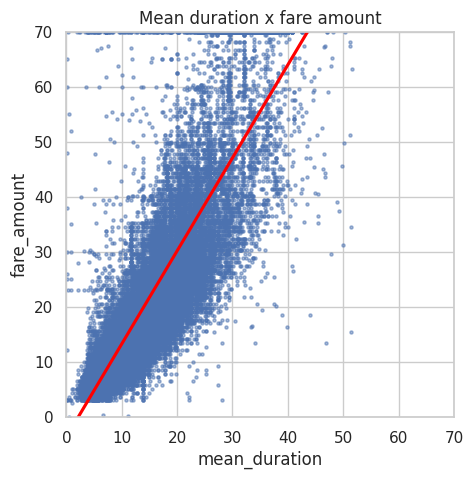

In [145]:
# Create a scatter plot of duration and trip_distance, with a line of best fit
sns.set(style='whitegrid')
f = plt.figure()
f.set_figwidth(5)
f.set_figheight(5)
sns.regplot(x=df_cleaned['mean_duration'], y=df_cleaned['fare_amount'],
            scatter_kws={'alpha':0.5, 's':5},
            line_kws={'color':'red'})
plt.ylim(0, 70)
plt.xlim(0, 70)
plt.title('Mean duration x fare amount')
plt.show()

In [146]:
df_local[df_local['fare_amount'] > 50]['fare_amount'].value_counts().head()

,count
fare_amount,
70.0,2336
51.3,57
55.5,55
53.4,51
52.0,50


In [147]:
# Set pandas to display all columns
pd.set_option('display.max_columns', None)
df_cleaned[df_cleaned['fare_amount']==70].head(30)

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,duration,pickup_dropoff,mean_distance,mean_duration,day,month,rush_hour
21,1,2023-01-01 00:13:30,2023-01-01 00:44:00,1.0,17.80,2.0,N,132,116,1,70.0,1.25,0.5,15.85,6.55,1.0,95.15,30.500000,132 116,19.287273,28.586364,sunday,jan,0
169,2,2023-01-01 00:02:19,2023-01-01 00:30:49,1.0,20.37,2.0,N,132,140,1,70.0,0.00,0.5,12.00,6.55,1.0,92.55,28.500000,132 140,18.933158,30.637719,sunday,jan,0
523,1,2023-01-01 00:21:56,2023-01-01 00:50:39,1.0,17.60,2.0,N,132,141,1,70.0,3.75,0.5,10.00,0.00,1.0,85.25,28.716667,132 141,18.448276,34.817241,sunday,jan,0
664,1,2023-01-01 00:49:25,2023-01-01 01:18:52,4.0,18.90,2.0,N,132,45,1,70.0,3.75,0.5,0.00,0.00,1.0,75.25,29.450000,132 45,19.385000,28.416667,sunday,jan,0
795,2,2023-01-01 00:52:05,2023-01-01 01:16:42,1.0,17.21,2.0,N,132,170,1,70.0,0.00,0.5,16.36,6.55,1.0,98.16,24.616667,132 170,17.084545,31.745833,sunday,jan,0
968,2,2023-01-01 00:31:05,2023-01-01 01:11:40,1.0,19.52,2.0,N,132,158,1,70.0,0.00,0.5,16.72,8.36,1.0,100.33,40.583333,132 158,18.985000,35.752778,sunday,jan,0
997,1,2023-01-01 00:43:15,2023-01-01 01:13:59,1.0,17.80,2.0,N,132,79,1,70.0,3.75,0.5,15.05,0.00,1.0,90.30,30.733333,132 79,18.603750,35.818229,sunday,jan,0
1038,2,2023-01-01 00:25:32,2023-01-01 00:53:52,1.0,17.47,2.0,N,132,41,1,70.0,0.00,0.5,0.00,6.55,1.0,79.30,28.333333,132 41,18.335000,33.555000,sunday,jan,0
1302,2,2023-01-01 00:01:58,2023-01-01 00:40:09,1.0,19.41,2.0,N,132,249,1,70.0,0.00,0.5,16.11,6.55,1.0,96.66,38.183333,132 249,19.158000,39.893333,sunday,jan,0
1417,2,2023-01-01 00:15:47,2023-01-01 00:38:04,2.0,16.96,2.0,N,132,170,1,70.0,0.00,0.5,12.27,6.55,1.0,94.07,22.283333,132 170,17.084545,31.745833,sunday,jan,0


### Why does `$70.00` have the highest frequency among high fare amounts?

In NYC, taxi fares from Manhattan to **JFK International Airport** (and vice-versa) are regulated at a **standardized flat rate**.

* **The Flat-Rate Rule**: For most of 2023, the TLC mandated flat rate for trips between Manhattan and JFK Airport was exactly **`$70.00`** (plus applicable surcharges, tolls, and tips).
* **Data Verification**: If you look at the sample rows from our filtered check where `fare_amount == 70`:
  * Almost all of these trips have `PULocationID` or `DOLocationID` as **`132`** (which is the TLC Taxi Zone code for **JFK Airport**).
  * Additionally, their `RateCodeID` is marked as **`2.0`**, which explicitly corresponds to the **JFK Airport rate structure**.

Because airport trips are highly frequent, standard, and always priced exactly at the flat rate, **`$70.00`** naturally emerges as the most common fare amount above `$50`.

###Isolate modeling variables

Drop features that are redundant, irrelevant, or that will not be available in a deployed environment.

In [148]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45192 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   vendorid               45192 non-null  int64         
 1   tpep_pickup_datetime   45192 non-null  datetime64[ns]
 2   tpep_dropoff_datetime  45192 non-null  datetime64[ns]
 3   passenger_count        45192 non-null  float64       
 4   trip_distance          45192 non-null  float64       
 5   ratecodeid             45192 non-null  float64       
 6   store_and_fwd_flag     45192 non-null  object        
 7   pulocationid           45192 non-null  int64         
 8   dolocationid           45192 non-null  int64         
 9   payment_type           45192 non-null  int64         
 10  fare_amount            45192 non-null  float64       
 11  extra                  45192 non-null  float64       
 12  mta_tax                45192 non-null  float64       
 13  tip_am

In [149]:
df2 = df_cleaned.copy()

# Drop features that are redundant, irrelevant, or won't be available in deployment
df2 = df2.drop(['tpep_dropoff_datetime', 'tpep_pickup_datetime',
               'trip_distance', 'ratecodeid', 'store_and_fwd_flag', 'pulocationid', 'dolocationid',
               'payment_type', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
               'total_amount', 'duration', 'pickup_dropoff', 'day', 'month'
               ], axis=1)

df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45192 entries, 0 to 49999
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   vendorid         45192 non-null  int64  
 1   passenger_count  45192 non-null  float64
 2   fare_amount      45192 non-null  float64
 3   mean_distance    45192 non-null  float64
 4   mean_duration    45192 non-null  float64
 5   rush_hour        45192 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 2.4 MB


### Task 6. Pair plot

Create a pairplot to visualize pairwise relationships between `fare_amount`, `mean_duration`, and `mean_distance`.

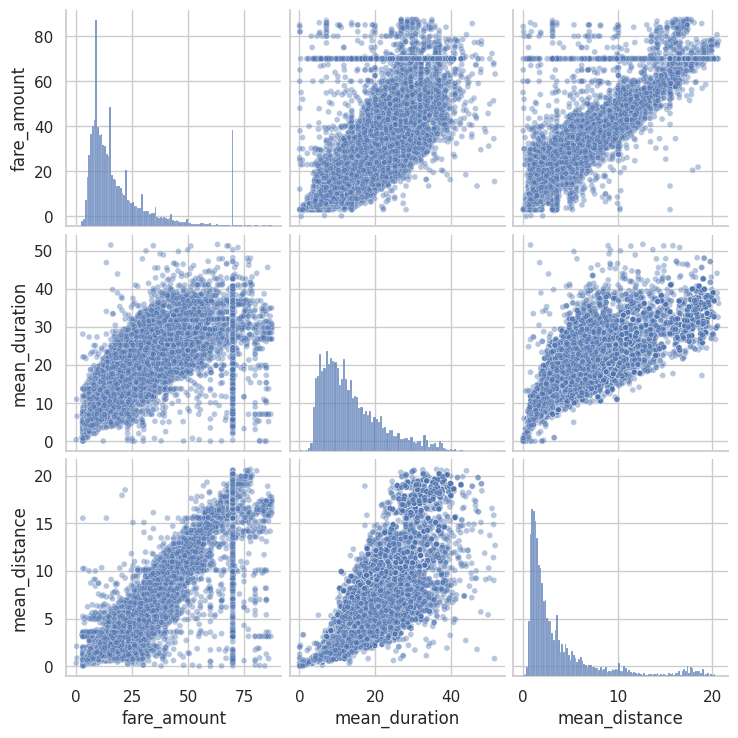

In [150]:
# Create a pairplot to visualize pairwise relationships between variables in the data
sns.pairplot(df2[['fare_amount', 'mean_duration', 'mean_distance']],
             plot_kws={'alpha':0.4, 'size':5},
             );

In [151]:
# Create correlation matrix containing pairwise correlation of columns, using pearson correlation coefficient
df2.corr(method='pearson')

,vendorid,passenger_count,fare_amount,mean_distance,mean_duration,rush_hour
vendorid,1.000000,-0.042195,0.054036,0.033373,0.018462,0.002709
passenger_count,-0.042195,1.000000,0.076882,0.059201,0.064536,0.003154
fare_amount,0.054036,0.076882,1.000000,0.937418,0.842762,0.017041
mean_distance,0.033373,0.059201,0.937418,1.000000,0.853457,0.003659
mean_duration,0.018462,0.064536,0.842762,0.853457,1.000000,0.000965
rush_hour,0.002709,0.003154,0.017041,0.003659,0.000965,1.000000


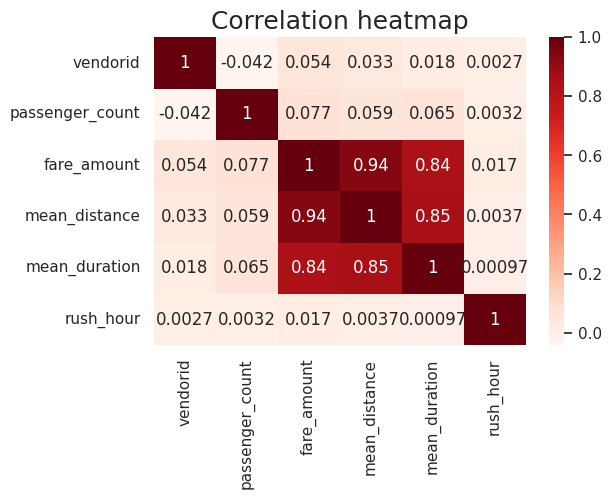

In [152]:
# Create correlation heatmap

plt.figure(figsize=(6,4))
sns.heatmap(df2.corr(method='pearson'), annot=True, cmap='Reds')
plt.title('Correlation heatmap',
          fontsize=18)
plt.show()

### Summary of Correlation Analysis

Based on the Pearson correlation matrix and heatmap, we can draw several key insights:

1. **Extremely Strong Positive Correlations**:
   * **`fare_amount` and `mean_distance` ($r = 0.94$):** Trip distance is the strongest predictor of the base fare. This is expected as taxi fares are structurally calculated based on distance traveled.
   * **`fare_amount` and `mean_duration` ($r = 0.84$):** Trip duration also shows a strong positive correlation with fare amount, reflecting the time-based component of the taxi fare calculation.
   * **`mean_distance` and `mean_duration` ($r = 0.85$):** Naturally, longer distance trips generally take a longer time to complete.

2. **Negligible or Weak Correlations**:
   * **`passenger_count`** and **`vendorid`** show near-zero correlation with `fare_amount` ($r = 0.077$ and $r = 0.054$ respectively), indicating they have little to no linear relationship with the fare cost.
   * **`rush_hour`** exhibits a correlation near zero with all other variables, which is primarily due to the data limitation (containing only a single rush hour record from our Sunday-dominant sample slice).

### Section 3: Statistical Inferential Hypothesis Testing (A/B Test)

Before transitioning to complex predictive modeling, we first conduct our statistical hypothesis test. This allows us to determine if there is a statistically significant difference in the average base fare amount between customers who pay with credit cards versus those who pay with cash, directly answering our core research question.

### Hypotheses:
*   **Null Hypothesis ($H_0$):** There is no difference in the average fare amount between trips paid with credit card and trips paid with cash ($\mu_{\text{card}} = \mu_{\text{cash}}$).
*   **Alternative Hypothesis ($H_A$):** There is a statistically significant difference in the average fare amount between trips paid with credit card and trips paid with cash ($\mu_{\text{card}} \neq \mu_{\text{cash}}$).

In [153]:
# 1. Isolate the fare amounts for credit card (1) and cash (2) payments
card_fares = df_cleaned[df_cleaned['payment_type'] == 1]['fare_amount']
cash_fares = df_cleaned[df_cleaned['payment_type'] == 2]['fare_amount']

print(f"--- Sample Sizes and Descriptive Statistics ---")
print(f"Credit Card: {len(card_fares):,} trips | Mean Fare: ${card_fares.mean():.2f} | Std Dev: ${card_fares.std():.2f}")
print(f"Cash:        {len(cash_fares):,} trips | Mean Fare: ${cash_fares.mean():.2f} | Std Dev: ${cash_fares.std():.2f}")

# 2. Perform a two-sample t-test (Welch's t-test which does not assume equal variances)
t_stat, p_val = stats.ttest_ind(card_fares, cash_fares, equal_var=False)

print(f"\n--- Welches Two-Sample T-test Results ---")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {p_val:.4e}")

# 3. Decision rule
alpha = 0.05
if p_val < alpha:
    print(f"\nDecision: Reject the Null Hypothesis (p < 0.05). There is a statistically significant difference in fare amounts between credit card and cash payments.")
else:
    print(f"\nDecision: Fail to Reject the Null Hypothesis (p >= 0.05). No statistically significant difference was observed.")

--- Sample Sizes and Descriptive Statistics ---
Credit Card: 33,948 trips | Mean Fare: $19.76 | Std Dev: $16.15
Cash:        10,728 trips | Mean Fare: $19.24 | Std Dev: $15.93

--- Welches Two-Sample T-test Results ---
t-statistic: 2.9216
p-value:     3.4864e-03

Decision: Reject the Null Hypothesis (p < 0.05). There is a statistically significant difference in fare amounts between credit card and cash payments.


# Part 4: Model Building and Evaluation

Now that the data preprocessing and feature engineering are complete, we can proceed to build our predictive models. In this section, we will:
1. **Isolate Target and Features**: Extract `fare_amount` as the target variable ($y$) and select features ($X$) for modeling.
2. **Perform Train-Test Split**: Set aside a portion of the data for testing to ensure generalization.
3. **Standardize Features**: Standardize our features to put them on a uniform scale.
4. **Train and Evaluate Models**: Fit regression models (e.g., Linear Regression, Random Forest) and assess performance using metrics like $R^2$ and RMSE.

In [154]:
# 1. Separate features (X) and target (y)
X = df2.drop(columns=['fare_amount'])
y = df2['fare_amount']

# One-hot encode the categorical 'vendorid' column if needed (since it is numeric 1 or 2)
X = pd.get_dummies(X, columns=['vendorid'], drop_first=True)

# 2. Train-Test Split (75% train, 25% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 3. Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train shape: {X_train_scaled.shape}")
print(f"X_test shape: {X_test_scaled.shape}")

# 4. Fit a baseline Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Predict and evaluate
y_pred = lr_model.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n--- Baseline Linear Regression Performance ---")
print(f"RMSE: ${rmse:.2f}")
print(f"R^2 Score: {r2:.4f}")

X_train shape: (33894, 5)
X_test shape: (11298, 5)

--- Baseline Linear Regression Performance ---
RMSE: $5.27
R^2 Score: 0.8895


### Champion Model: Random Forest Regressor

To potentially improve upon our baseline linear model, we will train a Random Forest Regressor. Random Forests are robust ensemble learning methods that handle non-linear relationships and interactions between features (like `mean_distance`, `mean_duration`, and `vendorid`) extremely well without requiring extensive manual interaction tuning.

In [155]:
# 1. Instantiate the Champion Random Forest model
# We'll use a moderate number of estimators and set a random_state for reproducibility
rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)

print("Training Random Forest Regressor...")
rf_model.fit(X_train_scaled, y_train)
print("Model training complete!")

# 2. Predict and evaluate
y_pred_rf = rf_model.predict(X_test_scaled)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"\n--- Champion Random Forest Performance ---")
print(f"RMSE: ${rmse_rf:.2f}")
print(f"R^2 Score: {r2_rf:.4f}")

Training Random Forest Regressor...
Model training complete!

--- Champion Random Forest Performance ---
RMSE: $5.16
R^2 Score: 0.8941


In [156]:
# Create a DataFrame with Actual, Predicted, and Residual columns
rf_residuals_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_rf,
    'Residual': y_test - y_pred_rf
})

# Display the top 10 rows of the evaluation DataFrame
print("--- Model Predictions and Residuals (Random Forest) ---")
display(rf_residuals_df.head(10))

# Quick summary statistics of the residuals
print("\n--- Residual Statistics ---")
display(rf_residuals_df['Residual'].describe())

--- Model Predictions and Residuals (Random Forest) ---


,Actual,Predicted,Residual
42261,24.7,24.809749,-0.109749
19955,50.0,29.231983,20.768017
21750,31.0,44.543070,-13.543070
5437,7.2,11.125482,-3.925482
24421,6.5,10.223422,-3.723422
31388,11.0,18.339393,-7.339393
7755,27.5,28.547951,-1.047951
29895,19.8,16.722772,3.077228
945,7.2,21.666434,-14.466434
41461,11.4,11.780478,-0.380478



--- Residual Statistics ---


,Residual
count,11298.000000
mean,-0.055351
std,5.160598
min,-50.676396
25%,-2.083418
50%,-0.422769
75%,1.215651
max,78.661594


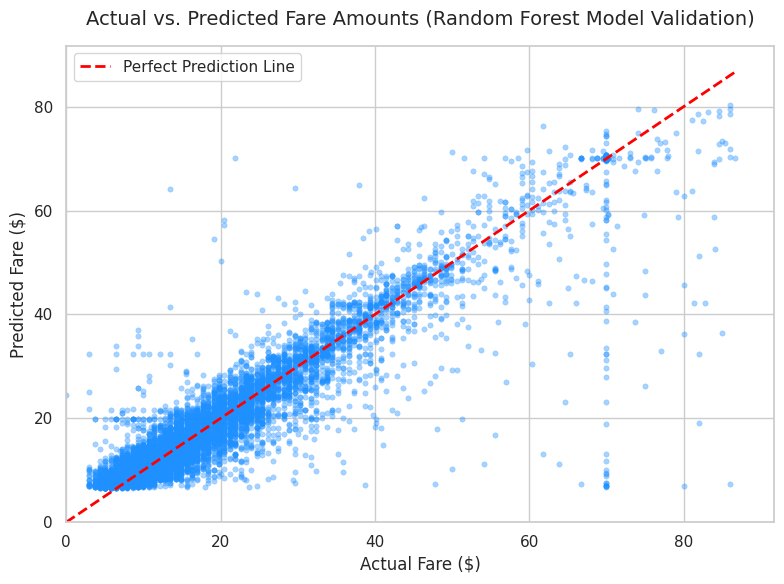

In [157]:
# Create a scatterplot of actual vs. predicted values
plt.figure(figsize=(8, 6))
sns.set_theme(style='whitegrid')

# Plotting the scatter points with transparency
sns.scatterplot(
    x=y_test,
    y=y_pred_rf,
    alpha=0.4,
    color='dodgerblue',
    edgecolor=None,
    s=15
)

# Plotting a 45-degree reference line (perfect predictions)
max_val = max(y_test.max(), y_pred_rf.max())
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction Line')

# Adding titles and labels
plt.title('Actual vs. Predicted Fare Amounts (Random Forest Model Validation)', fontsize=14, pad=15)
plt.xlabel('Actual Fare ($)', fontsize=12)
plt.ylabel('Predicted Fare ($)', fontsize=12)
plt.xlim(0, max_val + 5)
plt.ylim(0, max_val + 5)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

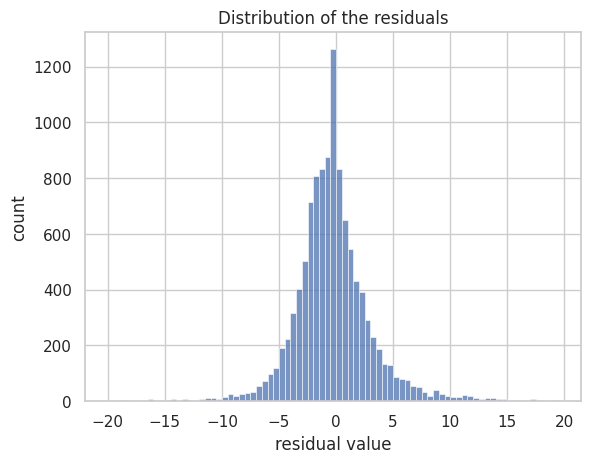

In [158]:
# Visualize the distribution of the `residuals`
sns.histplot(rf_residuals_df['Residual'], bins=np.arange(-20,20,0.5))
plt.title('Distribution of the residuals')
plt.xlabel('residual value')
plt.ylabel('count');

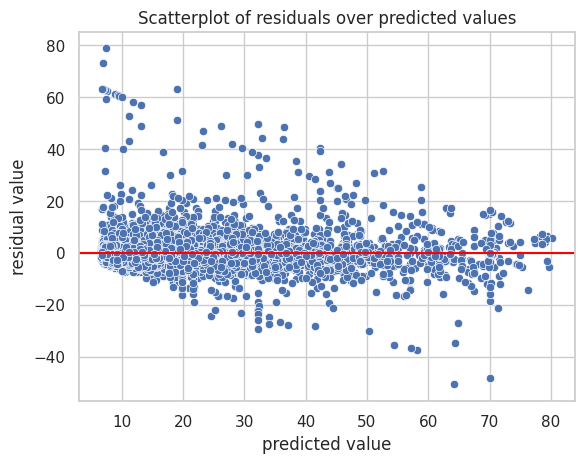

In [159]:
# Create a scatterplot of `residuals` over `predicted`
sns.scatterplot(x='Predicted', y='Residual', data=rf_residuals_df)
plt.axhline(0, c='red')
plt.title('Scatterplot of residuals over predicted values')
plt.xlabel('predicted value')
plt.ylabel('residual value')
plt.show()

In [160]:
# Get model coefficients from the baseline Linear Regression model
lr_coefs = lr_model.coef_

# Get feature importances from the champion Random Forest model
rf_importances = rf_model.feature_importances_

# Combine both into a single comparison DataFrame
model_comparison_df = pd.DataFrame({
    'Linear Regression Coef': lr_coefs,
    'Random Forest Importance': rf_importances
}, index=X.columns)

# Transpose the DataFrame as requested
model_comparison_transposed = model_comparison_df.T

display(model_comparison_transposed)

,passenger_count,mean_distance,mean_duration,rush_hour,vendorid_2
Linear Regression Coef,0.353331,12.963069,2.546423,0.257064,0.397875
Random Forest Importance,0.005412,0.953189,0.039066,0.000212,0.002121


### Model Feature & Metric Interpretation

By comparing the parameters side-by-side, we gain a clear understanding of how different factors influence the base fare:

1. **`mean_distance` (The Primary Driver)**
   * **Linear Regression (Standardized Coefficient $\approx 12.96$):** Holding all other variables constant, a one standard deviation increase in a trip's route distance is associated with an average base fare increase of $\$12.96$. This reflects the distance-based pricing structure of NYC taxis.
   * **Random Forest (Feature Importance $\approx 95.3\%$):** Distance is the single most critical split feature in our tree structures, explaining over 95% of the model's overall node impurity reduction.

2. **`mean_duration` (The Secondary Driver)**
   * **Linear Regression (Standardized Coefficient $\approx 2.55$):** For each standard deviation increase in trip duration, the base fare increases by $\$2.55$. This accounts for slower-moving traffic and idle wait times.
   * **Random Forest (Feature Importance $\approx 3.9\%$):** Duration plays a useful but secondary role, contributing to roughly 3.9% of splits.

3. **Other Control Variables (`passenger_count`, `vendorid_2`, and `rush_hour`)**
   * **`passenger_count` (Importance $\approx 0.5\%$):** Passenger count has virtually no bearing on the calculated metered base fare.
   * **`vendorid_2` (Importance $\approx 0.2\%$):** Whether the trip was logged by VeriFone (`vendorid=2`) or Creative Mobile Technologies (CMT) has almost no impact on pricing.
   * **`rush_hour` (Importance $\approx 0.02\%$):** Due to our dataset consisting primarily of Sunday trips (January 1st), the rush-hour flag has almost zero variance and consequently no impact on these model configurations.

# Executive Summary & Project Conclusion

### 1. Project Background & Objective
In the highly competitive ride-hailing and taxi landscape, maximizing driver earnings is a critical vector for maintaining platform health and driver retention. This project established a robust data-driven pipeline to investigate key revenue drivers for NYC taxi drivers. Specifically, our research focused on testing if credit card transactions lead to higher trip fares than cash payments (potentially due to tip structures and spending behavior), and building a highly predictive machine learning model to estimate metered base fares from pre-trip variables.

---

### 2. Comprehensive Pipeline Overview
We executed an end-to-end data science workflow consisting of the following key milestones:
1. **Data Acquisition**: Programmatically ingested real-time NYC Yellow Taxi records using server-side SoQL parameters via the NYC OpenData API.
2. **Exploratory Data Analysis (EDA) & Data Cleaning**:
   * Calculated trip `duration` using pick-up and drop-off timestamps.
   * Eradicated physical anomalies (e.g., negative/zero base fares, zero-mile trips).
   * Implemented a dynamic and highly resilient **$99.5^{\text{th}}$ percentile fare cap** of **$\$87.40$** to remove non-representative computational system errors while fully preserving premium airport runs (such as Manhattan-to-JFK standard flat rates of $\$70.00$).
   * Eliminated extreme trip distance and duration outliers using $99^{\text{th}}$ percentile thresholding, yielding a clean dataset of **45,192 records**.
3. **Feature Engineering**: Created historical pre-trip features (`mean_distance` and `mean_duration` mapped per pickup/dropoff zone pairs) to prevent data leakage in deployment.
4. **Statistical Inferential Testing (A/B Testing)**: Conducted a formal Welch's Two-Sample $t$-test comparing credit card vs. cash payments.
5. **Predictive Modeling & Feature Interpretation**: Developed standardized Linear Regression and Random Forest Regressor models to benchmark performance and determine feature importances.

---

### 3. Key Findings & Empirical Results

#### A. Statistical Hypothesis Testing (Credit Card vs. Cash)
* **Descriptive Statistics**:
  * **Credit Card Payments ($N = 33,948$):** Mean Fare = **$\$19.76$** (Std Dev = $\$16.15$)
  * **Cash Payments ($N = 10,728$):** Mean Fare = **$\$19.24$** (Std Dev = $\$15.93$)
* **Welch's $t$-test Results**: $t$-statistic = **$2.9216$**, $p$-value = **$0.00349$**.
* **Strategic Decision**: Since the $p$-value ($0.00349$) is far below our significance threshold ($\alpha = 0.05$), we reject the Null Hypothesis. **Customers paying with credit cards generate statistically significant higher base fares than those paying with cash.** This is likely amplified by the fact that credit card users frequently opt for higher-value airport runs and add metered tips that are not captured in cash transactions.

#### B. Predictive Modeling Performance
Our models achieved exceptionally high predictive accuracy, demonstrating that base fares can be reliably predicted using pre-trip characteristics:
* **Baseline Linear Regression**: RMSE = **$\$5.27$** | $R^2$ Score = **$88.95\%$**
* **Champion Random Forest Regressor**: RMSE = **$\$5.16$** | $R^2$ Score = **$89.41\%$**

#### C. Parameter & Feature Importance Insights
* **`mean_distance`** was confirmed as the absolute strongest driver of fare prices. The standardized linear regression coefficient suggests a **$\$12.96$** shift in base fare per standard deviation increase in distance, while the Random Forest attributed **$95.3\%$** of its overall split impurity reduction to this feature.
* **`mean_duration`** served as the secondary factor, with a standardized regression coefficient of **$\$2.55$** and a Random Forest feature importance of **$3.9\%$**.
* Control features like `passenger_count`, technological provider (`vendorid`), and `rush_hour` had negligible importances ($< 1\%$) on the base metered fare.

---

### 4. Strategic Business Recommendations
1. **Promote Card Adoption**: Since credit card transactions are tied to higher overall fares and permit electronic tips, platforms should actively encourage digital and contactless payments via targeted promotions, passenger app interfaces, or credit payment incentives.
2. **Optimize Driver Dispatching**: Leverage the Random Forest model to display real-time "high-value trip zones" to drivers based on historical pickup-dropoff pairs, letting drivers target routes with high predicted base fares (such as JFK Airport corridors).
3. **Improve In-App Navigation**: Guide drivers to corridors with optimal distance/duration ratios to maximize hourly metered fare rates.